# AHS rt: howl sim → AHS → plots → latency

Tech validation, not contract delivery.

- Real C++ only: rt-audio `Engine`/`Worker` + `release/ahs/*` via `ahs_bridge` (`notebook/ahs_bridge.cpp`). Py = build, I/O, plots.
- Loop @48 kHz: `mic = src + g·(path ∗ speaker)`; speaker = engine out, clip ±1; path sees speaker 1 callback late (device buffer).
- Steps 1–3 = closed loop (AHS inside the simulated system; AFC learns from its own speaker output). Step 4 = open loop on purpose (see §4).
- Releases: `v7-c0291dd1e` (= AHS bit-exact), `v7-lowlat-c0291dd1e` (no 64-smp wait), `v7-lowlat-fir-c0291dd1e` (+ FIR resampler, algo change), `v7-split-c0291dd1e` (detector on worker).
- Synthetic paths + AHS test clips (speech female/male, music). ≠ real room. All timings: dev Mac, not isolated → ref only.
- Full run ≈ 10 min (stability sweep + ahs_sim comparison).

Needs: C++20 compiler, `numpy scipy matplotlib ipython`. Example audio: `../AHS/testdata/speech_female.wav` (fallback synthetic).

In [1]:
# 0. build: make libs + compile ahs_bridge
import sys, time
from pathlib import Path
here = next(p for p in [Path.cwd(), Path.cwd() / "notebook"] if (p / "ahs_rt.py").exists())
sys.path.insert(0, str(here))
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Audio, display
import ahs_rt as A
print(A.build())
RELEASES = A.releases()
COLORS = {"passthrough": "tab:red", "v7-c0291dd1e": "tab:blue",
          "v7-lowlat-c0291dd1e": "tab:green", "v7-lowlat-fir-c0291dd1e": "tab:orange",
          "v7-split-c0291dd1e": "tab:purple"}
RELEASES

/Users/fuchienzou/Documents/Quencher/rt-audio/build/notebook/ahs_bridge


['v7-c0291dd1e',
 'v7-lowlat-c0291dd1e',
 'v7-lowlat-fir-c0291dd1e',
 'v7-split-c0291dd1e']

## 1. example audio → howling data

Speech → 48 kHz. Path: 2 ms direct + 150 ms T60 tail, 50 ms, peak |H| = 1 → loop gain dB rel. path peak.
Gain schedule: −20 dB (stable) until 4 s, then `G2_DB`. Engine = passthrough → howl.

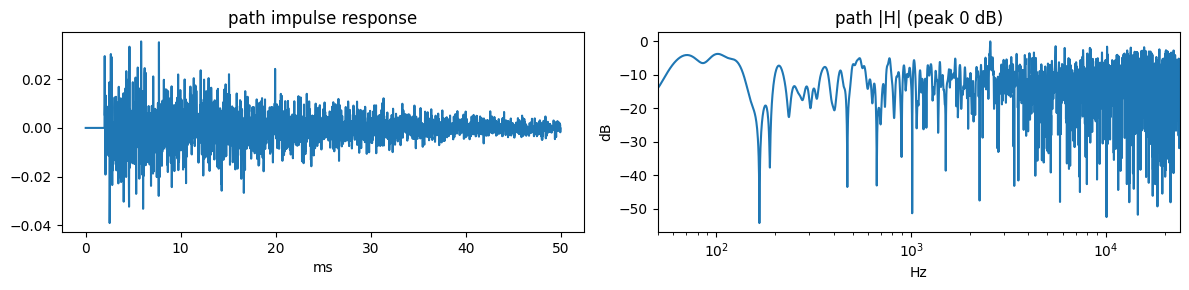

speech_female.wav 12.0 s {'release': 'passthrough', 'split': False, 'paced': False, 'callbacks': 4500, 'analysis_dropped': 0, 'commands_dropped': 0, 'commands_applied': 0, 'callback_us': {'mean': 0.1313, 'p50': 0.084, 'p99': 1.042, 'max': 34.708, 'n': 4500}}


PosixPath('/Users/fuchienzou/Documents/Quencher/rt-audio/notebook/out/howling_spk.wav')

In [2]:
src, src_name = A.load_example()
path = A.make_path()
G1_DB, G2_DB, STEP_S, FRAMES = -20.0, 6.0, 4.0, 128

f = np.fft.rfftfreq(1 << 16, 1 / A.FS); H = np.abs(np.fft.rfft(path, 1 << 16))
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(np.arange(path.size) / A.FS * 1e3, path); ax[0].set(xlabel="ms", title="path impulse response")
ax[1].semilogx(f[1:], 20 * np.log10(H[1:] + 1e-9)); ax[1].set(xlabel="Hz", ylabel="dB", title="path |H| (peak 0 dB)", xlim=(50, 24000))
plt.tight_layout(); plt.show()

howl = A.run_loop("passthrough", src, path, G1_DB, G2_DB, STEP_S, FRAMES)
print(src_name, f"{src.size / A.FS:.1f} s", howl["stats"])
A.save_wav("src", src); A.save_wav("howling_mic", howl["mic"]); A.save_wav("howling_spk", howl["spk"])

## 2. howling data → AHS rt system → AHS data

Same src, same path, same gains; AHS release in the loop (feedback suppression only works in a closed loop: AFC needs the real speaker→mic path).
Split runs real-time paced (worker must keep up) → ~12 s wall.

In [3]:
runs = {"passthrough": howl}
for rel in RELEASES:
    t = time.time()
    runs[rel] = A.run_loop(rel, src, path, G1_DB, G2_DB, STEP_S, FRAMES)
    A.save_wav(f"ahs_{rel}", runs[rel]["spk"])
    s = runs[rel]["stats"]
    print(f"{rel:<22} {time.time() - t:5.1f} s wall  drops Q1/Q2 {s['analysis_dropped']}/{s['commands_dropped']}  "
          f"cmds applied {s['commands_applied']}  cb mean {s['callback_us']['mean']:.1f} us")

v7-c0291dd1e             1.0 s wall  drops Q1/Q2 0/0  cmds applied 0  cb mean 18.7 us


v7-lowlat-c0291dd1e      1.0 s wall  drops Q1/Q2 0/0  cmds applied 0  cb mean 19.2 us


v7-lowlat-fir-c0291dd1e   0.9 s wall  drops Q1/Q2 0/0  cmds applied 0  cb mean 16.2 us


v7-split-c0291dd1e      12.0 s wall  drops Q1/Q2 0/0  cmds applied 2999  cb mean 59.7 us


### 2b. multiple sources + listen

Same path, same gain step, 3 AHS test clips (speech female/male, music). Split skipped (real-time paced).
Files: `notebook/out/<source>_<version>.wav` (48 kHz 16-bit). Players below are 16 kHz to keep the notebook small.
Howl ≈ full scale → start quiet.

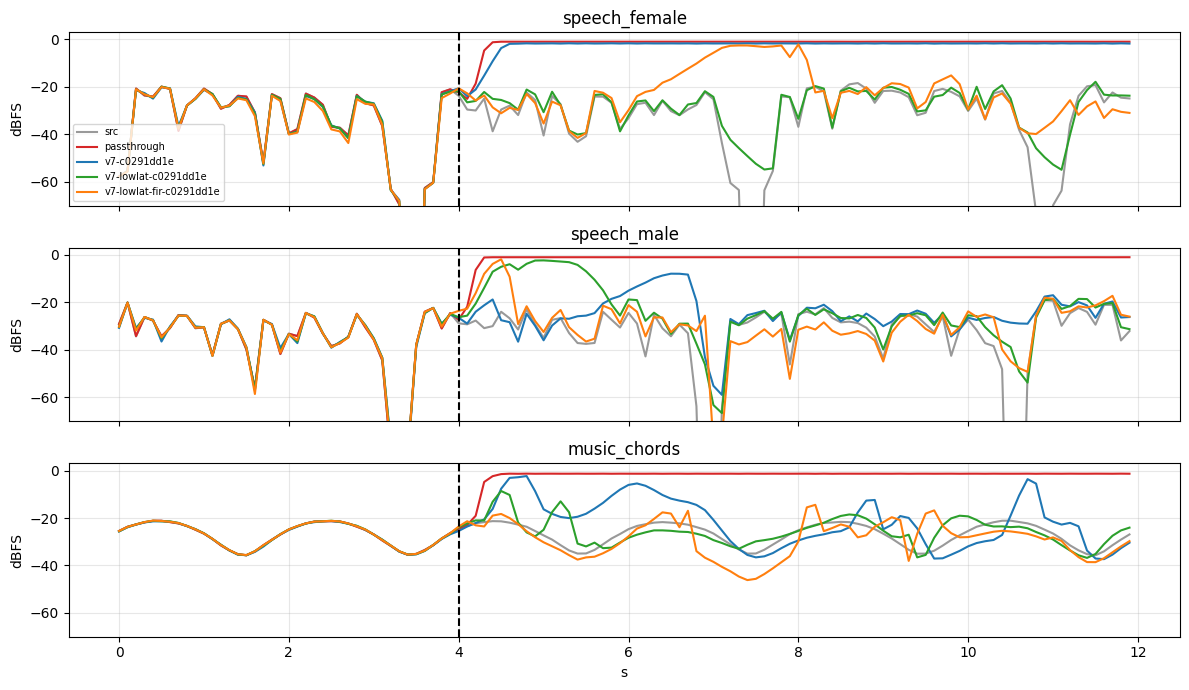

,src,passthrough,v7,v7-lowlat,v7-lowlat-fir
speech_female,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
speech_male,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
music_chords,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.


files:
  ahs_v7-c0291dd1e.wav
  ahs_v7-lowlat-c0291dd1e.wav
  ahs_v7-lowlat-fir-c0291dd1e.wav
  ahs_v7-split-c0291dd1e.wav
  howling_mic.wav
  howling_spk.wav
  music_chords_passthrough.wav
  music_chords_src.wav
  music_chords_v7-lowlat-fir.wav
  music_chords_v7-lowlat.wav
  music_chords_v7.wav
  ourpath1.wav
  ourpath2.wav
  speech_female_passthrough.wav
  speech_female_src.wav
  speech_female_v7-lowlat-fir.wav
  speech_female_v7-lowlat.wav
  speech_female_v7.wav
  speech_male_passthrough.wav
  speech_male_src.wav
  speech_male_v7-lowlat-fir.wav
  speech_male_v7-lowlat.wav
  speech_male_v7.wav
  src.wav


In [4]:
from scipy.signal import resample_poly
from IPython.display import HTML
VERS = ["passthrough", "v7-c0291dd1e", "v7-lowlat-c0291dd1e", "v7-lowlat-fir-c0291dd1e"]
multi = {}
for sname, spath in A.SOURCES.items():
    s, _ = A.load_example(spath)
    multi[sname] = {"src": s}
    A.save_wav(f"{sname}_src", s)
    for v in VERS:
        y = A.run_loop(v, s, path, G1_DB, G2_DB, STEP_S, FRAMES)["spk"]
        multi[sname][v] = y
        A.save_wav(f"{sname}_{v.replace('-c0291dd1e', '')}", y)

fig, ax = plt.subplots(len(multi), 1, figsize=(12, 7), sharex=True)
for a_, (sname, d) in zip(ax, multi.items()):
    t, db = A.rms_db(d["src"]); a_.plot(t, db, c="0.6", label="src")
    for v in VERS:
        t, db = A.rms_db(d[v]); a_.plot(t, db, c=COLORS[v], label=v)
    a_.axvline(STEP_S, ls="--", c="k"); a_.set(ylabel="dBFS", ylim=(-70, 3), title=sname); a_.grid(alpha=.3)
ax[0].legend(loc="lower left", fontsize=7); ax[-1].set_xlabel("s"); plt.tight_layout(); plt.show()

# resampling can overshoot +-1 on clipped howl -> clip again
play = lambda x: Audio(np.clip(resample_poly(x, 1, 3), -1, 1), rate=16000, normalize=False)._repr_html_()
cols = ["src", *VERS]
rows = "".join(f"<tr><th>{s}</th>" + "".join(f"<td>{play(d[c])}</td>" for c in cols) + "</tr>" for s, d in multi.items())
display(HTML("<table><tr><th></th>" + "".join(f"<th>{c.replace('-c0291dd1e', '')}</th>" for c in cols) + "</tr>" + rows + "</table>"))
print("files:", *sorted(p.name for p in A.OUT.glob("*.wav")), sep="\n  ")

## 3. plots

RMS over time, waveforms, spectrograms. Dashed = gain step.

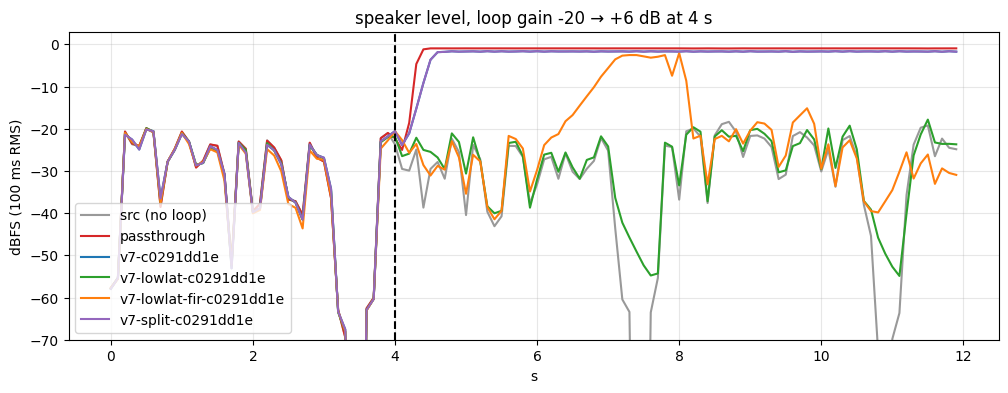

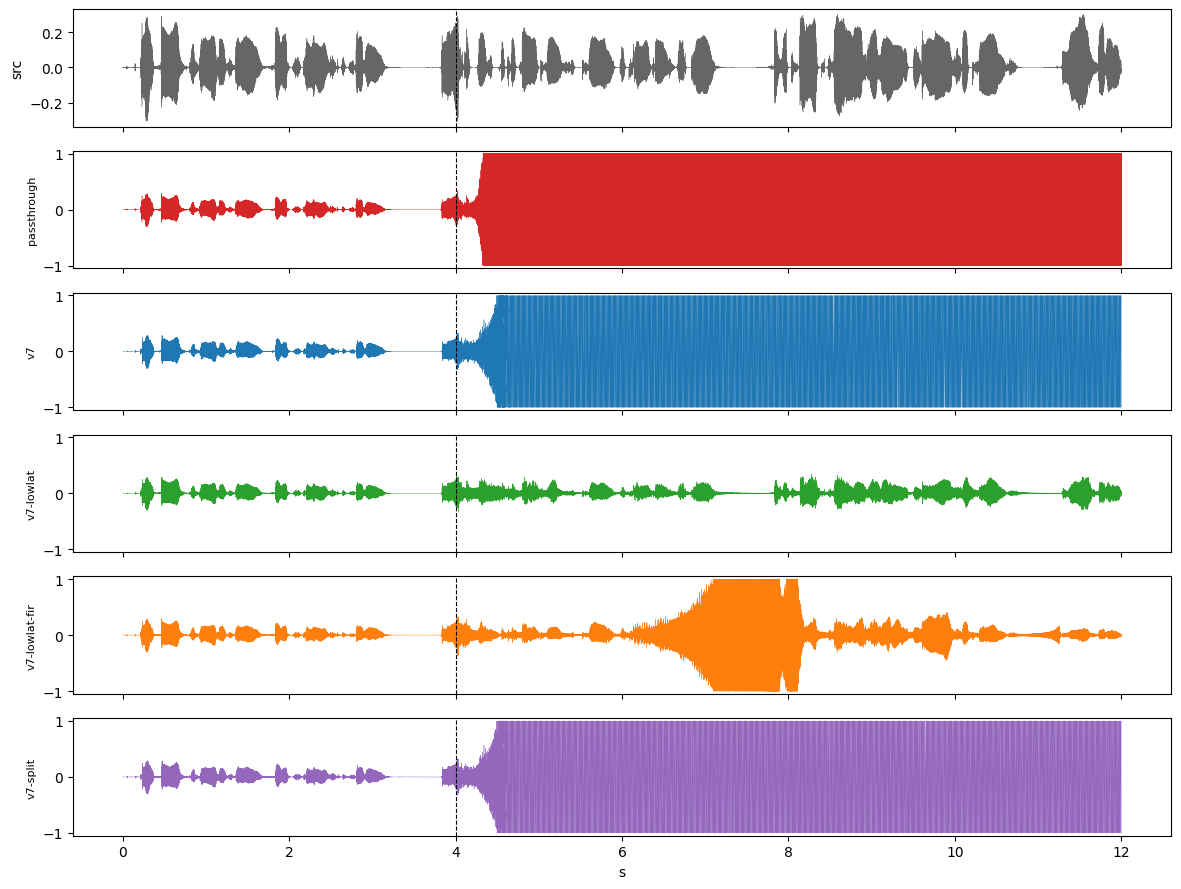

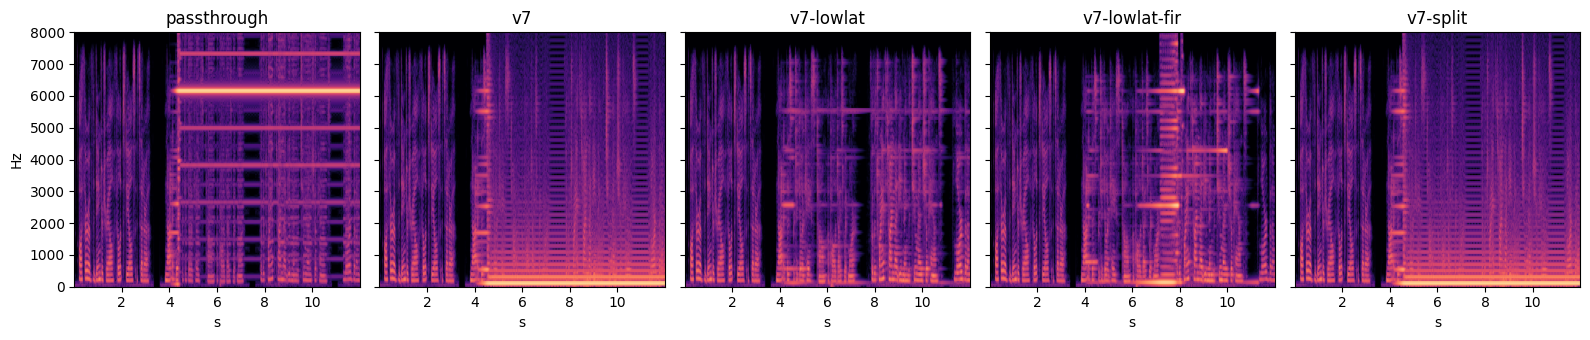

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
t, d = A.rms_db(src); ax.plot(t, d, color="0.6", label="src (no loop)")
for name, r in runs.items():
    t, d = A.rms_db(r["spk"]); ax.plot(t, d, color=COLORS[name], label=name)
ax.axvline(STEP_S, ls="--", c="k"); ax.set(xlabel="s", ylabel="dBFS (100 ms RMS)", ylim=(-70, 3),
       title=f"speaker level, loop gain {G1_DB:+.0f} → {G2_DB:+.0f} dB at {STEP_S:.0f} s")
ax.legend(loc="lower left"); ax.grid(alpha=.3); plt.show()

names = ["passthrough", *RELEASES]
fig, ax = plt.subplots(len(names) + 1, 1, figsize=(12, 9), sharex=True)
tt = np.arange(src.size) / A.FS
ax[0].plot(tt, src, lw=.3, c="0.4"); ax[0].set_ylabel("src")
for a_, n in zip(ax[1:], names):
    y = runs[n]["spk"]; a_.plot(np.arange(y.size) / A.FS, y, lw=.3, c=COLORS[n]); a_.set_ylabel(n.replace("-c0291dd1e", ""), fontsize=8)
    a_.set_ylim(-1.05, 1.05)
for a_ in ax: a_.axvline(STEP_S, ls="--", c="k", lw=.8)
ax[-1].set_xlabel("s"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, len(names), figsize=(16, 3.5), sharey=True)
for a_, n in zip(ax, names):
    a_.specgram(runs[n]["spk"], NFFT=1024, Fs=A.FS, noverlap=512, vmin=-120, vmax=-10, cmap="magma")
    a_.set(title=n.replace("-c0291dd1e", ""), xlabel="s", ylim=(0, 8000))
ax[0].set_ylabel("Hz"); plt.tight_layout(); plt.show()

### 3b. stability: 6 paths × 2 evaluation modes

Max stable loop gain (dB above passthrough's), per path seed 1–6, source = speech_female.
- **strict**: −20 dB → g at 4 s, hard clip, fail if any 250 ms after step > −12 dBFS.
- **ahs_sim**: constant g, `tanh(g·out)` speaker, fail if last 1 s RMS ∉ [0.25, 4]× src (ahs_sim's criterion).

One path decides nothing: same release swings ~8 dB across paths. Read the mean, not a single row. ~6 min.

[strict]  seed             v7     v7-lowlat v7-lowlat-fir
             1             +2            +4            +3
             2             +4            +3            +7
             3             +2            +2            +2
             4             +3            +4            +2
             5             +1            +2            -1
             6             +2            +2            +3
          mean          +2.33         +2.83         +2.67


[ahs_sim]  seed             v7     v7-lowlat v7-lowlat-fir
             1             +2            +6            +9
             2             +9           +10           +12
             3             +5            +2            +3
             4            +10           +10            +5
             5            +10            +8            +9
             6            +10            +9            +8
          mean          +7.67         +7.50         +7.67


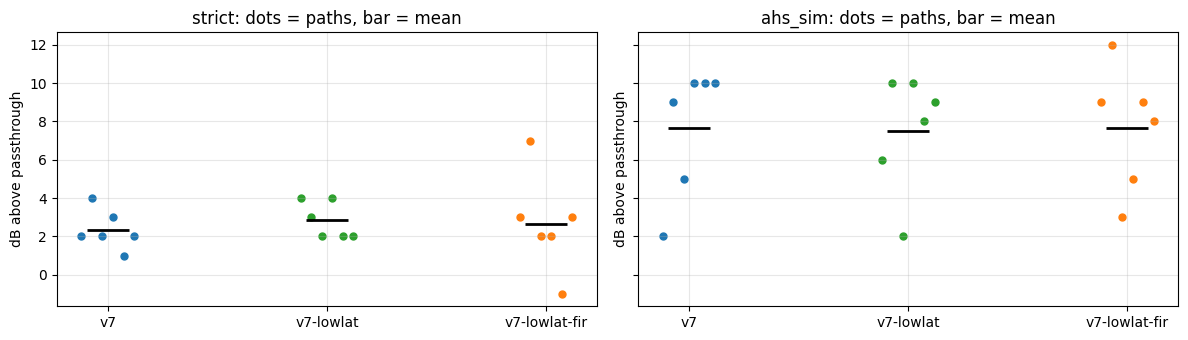

In [6]:
SEEDS = range(1, 7)
SWEEP = ["v7-c0291dd1e", "v7-lowlat-c0291dd1e", "v7-lowlat-fir-c0291dd1e"]
margin = {m: {v: [] for v in SWEEP} for m in A.MODES}
for m in A.MODES:
    for seed in SEEDS:
        p = A.make_path(seed=seed)
        base = A.max_stable_gain("passthrough", src, p, m)
        for v in SWEEP:
            margin[m][v].append(A.max_stable_gain(v, src, p, m) - base)
    print(f"[{m}]  seed " + "".join(f"{v.replace('-c0291dd1e', ''):>14}" for v in SWEEP))
    for i, seed in enumerate(SEEDS):
        print(f"{'':<10}{seed:>4} " + "".join(f"{margin[m][v][i]:+14.0f}" for v in SWEEP))
    print(f"{'':<10}mean " + "".join(f"{np.mean(margin[m][v]):+14.2f}" for v in SWEEP))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for a_, m in zip(ax, A.MODES):
    for k, v in enumerate(SWEEP):
        vals = np.array(margin[m][v])
        a_.scatter(np.full(vals.size, k) + np.linspace(-.12, .12, vals.size), vals, c=COLORS[v], s=25)
        a_.errorbar(k, vals.mean(), fmt="_", c="k", ms=30, mew=2)
    a_.set_xticks(range(len(SWEEP)), [v.replace("-c0291dd1e", "") for v in SWEEP])
    a_.set(title=f"{m}: dots = paths, bar = mean", ylabel="dB above passthrough"); a_.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 3c. why `ahs_sim` reports +13.9 dB and this notebook ~+3–8 dB

`ahs_sim` (AHS's own 16 kHz closed-loop sim, built from the vendored commit) vs this loop. Change one thing at a time.
Skipped if `../AHS` repo / commit is not available. ~2 min.

ahs_sim, its own criterion (AHS margin over bypass):
  baseline (synth 200 taps, drift 0.2, delay 64) +13.93 dB
  static path                                    +14.47 dB
  long synth path 800 taps (50 ms)               +10.24 dB
  OUR path seed 1 (--rir)                         +8.32 dB
  OUR path seed 2 (--rir)                         +7.69 dB



ahs_sim loop-delay sweep (static path): 4.1 ms +20.1, 5.0 ms +12.7, 6.0 ms +15.2, 7.0 ms +14.3, 8.0 ms +14.5, 10.0 ms +11.8, 12.0 ms +14.2

ahs_sim's path inside THIS loop, ahs_sim criterion, constant gain:


  speaker clip: v7 +5  v7-lowlat +12  v7-lowlat-fir +6 dB


  speaker tanh: v7 +9  v7-lowlat +12  v7-lowlat-fir +19 dB


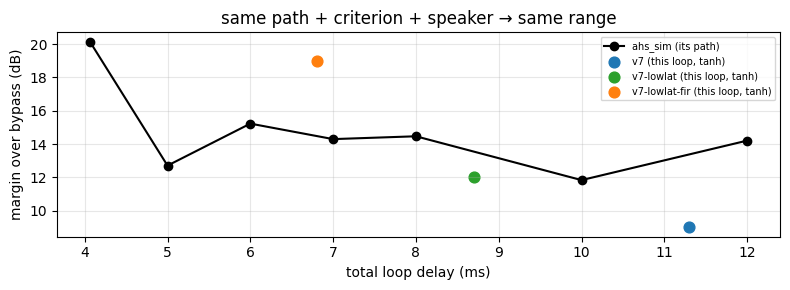

In [7]:
sim = A.build_ahs_sim()
if sim is None:
    print("ahs_sim unavailable (needs ../AHS with commit", A.AHS_COMMIT, ") - skipped")
else:
    wav = A.SOURCES["speech_female"]
    def margin_sim(*args):
        r = A.ahs_sim_msg(wav, *args); return r["afc+notch+guard"] - r["bypass"]
    rows = [("baseline (synth 200 taps, drift 0.2, delay 64)", margin_sim()),
            ("static path", margin_sim("--path-drift", 0)),
            ("long synth path 800 taps (50 ms)", margin_sim("--synth-taps", 800, "--path-drift", 0))]
    for seed in (1, 2):
        rows.append((f"OUR path seed {seed} (--rir)", margin_sim("--rir", A.path_wav16(A.make_path(seed=seed), f"ourpath{seed}"), "--path-drift", 0)))
    print("ahs_sim, its own criterion (AHS margin over bypass):")
    for name, v in rows: print(f"  {name:<46} {v:+6.2f} dB")

    delays = [1, 16, 32, 48, 64, 96, 128]
    dm = [margin_sim("--path-drift", 0, "--loop-delay", d) for d in delays]
    print("\nahs_sim loop-delay sweep (static path): " + ", ".join(f"{(d + 64) / 16:.1f} ms {v:+.1f}" for d, v in zip(delays, dm)))

    h_sim = A.ahs_sim_path48(wav)
    print("\nahs_sim's path inside THIS loop, ahs_sim criterion, constant gain:")
    res = {}
    for spk in ("clip", "tanh"):
        def msg(v):
            best = None
            for g in range(-6, 31):
                y = A.run_loop(v, src, h_sim, g, g, 0.0, speaker=spk)["spk"]
                r = np.sqrt(np.mean(y[-A.FS:].astype(np.float64) ** 2)); s_ = np.sqrt(np.mean(src.astype(np.float64) ** 2))
                if not (0.25 * s_ <= r <= 4 * s_): return best
                best = g
            return best
        b = msg("passthrough"); res[spk] = {v: msg(v) - b for v in SWEEP}
        print(f"  speaker {spk}: " + "  ".join(f"{v.replace('-c0291dd1e', '')} {res[spk][v]:+.0f}" for v in SWEEP) + " dB")
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot([(d + 64) / 16 for d in delays], dm, "o-", c="k", label="ahs_sim (its path)")
    loopms = {"v7-c0291dd1e": 11.3, "v7-lowlat-c0291dd1e": 8.7, "v7-lowlat-fir-c0291dd1e": 6.8}  # device 2.67 + code + path 2 ms
    for v in SWEEP: ax.scatter(loopms[v], res["tanh"][v], c=COLORS[v], s=60, label=f"{v.replace('-c0291dd1e', '')} (this loop, tanh)")
    ax.set(xlabel="total loop delay (ms)", ylabel="margin over bypass (dB)", title="same path + criterion + speaker → same range")
    ax.legend(fontsize=7); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## 4. latency per module + communication

Two kinds — don't add them:
- **audio path** = mic→speaker delay of the code (contract E2E = this + device in/out buffers).
- **control path** (split only) = how late a detection takes effect. Audio never takes it.
Compute time ≠ latency while < callback period (2.667 ms @128); only xrun risk.

Speex Q4 48→16→48 alone: 4.000 ms
release                     f=32      f=64     f=128     f=256
v7-c0291dd1e              7.333     6.667     6.667     6.667 
v7-lowlat-c0291dd1e       4.000     4.000     4.000     4.000 
v7-lowlat-fir-c0291dd1e    2.146     2.146     2.146     2.146 
v7-split-c0291dd1e        7.333     6.667     6.667     6.667 


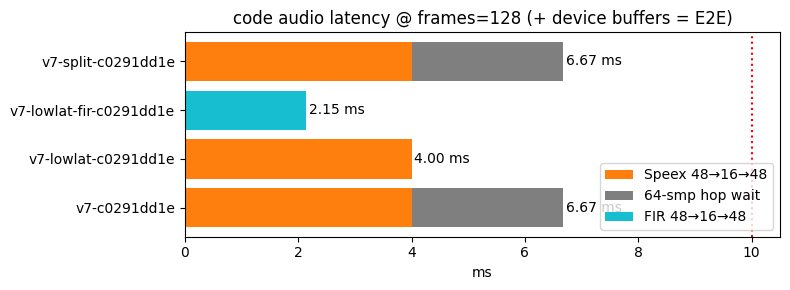

In [8]:
# 4a. audio-path latency: impulse, OPEN loop on purpose (feedback would recirculate the impulse)
frames_list = [32, 64, 128, 256]
lat = {rel: [A.latency(rel, fr)["lag_ms"] for fr in frames_list] for rel in RELEASES}
spx = A.resampler_lag()["lag_ms"]
print(f"Speex Q4 48→16→48 alone: {spx:.3f} ms")
print(f"{'release':<22}" + "".join(f"{f'f={fr}':>10}" for fr in frames_list))
for rel, v in lat.items(): print(f"{rel:<22}" + "".join(f"{x:>9.3f} " for x in v))

i128 = frames_list.index(128)
fig, ax = plt.subplots(figsize=(8, 3))
for k, rel in enumerate(RELEASES):
    tot = lat[rel][i128]
    rs = (110 + 96) / 2 / 48 if "fir" in rel else spx   # FIR group delay (55+48 smp) vs Speex
    wait = max(tot - rs, 0)
    ax.barh(k, rs, color="tab:cyan" if "fir" in rel else "tab:orange",
            label=("FIR 48→16→48" if "fir" in rel else ("Speex 48→16→48" if k == 0 else None)))
    ax.barh(k, wait, left=rs, color="tab:gray", label="64-smp hop wait" if k == 0 else None)
    ax.text(tot + .05, k, f"{tot:.2f} ms", va="center")
ax.set_yticks(range(len(RELEASES)), RELEASES); ax.set(xlabel="ms", title="code audio latency @ frames=128 (+ device buffers = E2E)")
ax.axvline(10, ls=":", c="r"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

speex_down       mean   2.799  p99   2.875 us   11.8%  callback
afc              mean  16.877  p99  29.458 us   71.4%  callback
notch            mean   0.328  p99   0.375 us    1.4%  callback
guard_env        mean   0.012  p99   0.042 us    0.1%  callback
detector         mean   1.849  p99   2.000 us    7.8%  cb (callback rel) / worker (split)
apply_detection  mean   0.021  p99   0.042 us    0.1%  callback
speex_up         mean   1.750  p99   1.833 us    7.4%  callback
total 23.64 us/hop ≈ 15.8 us per 128-frame callback


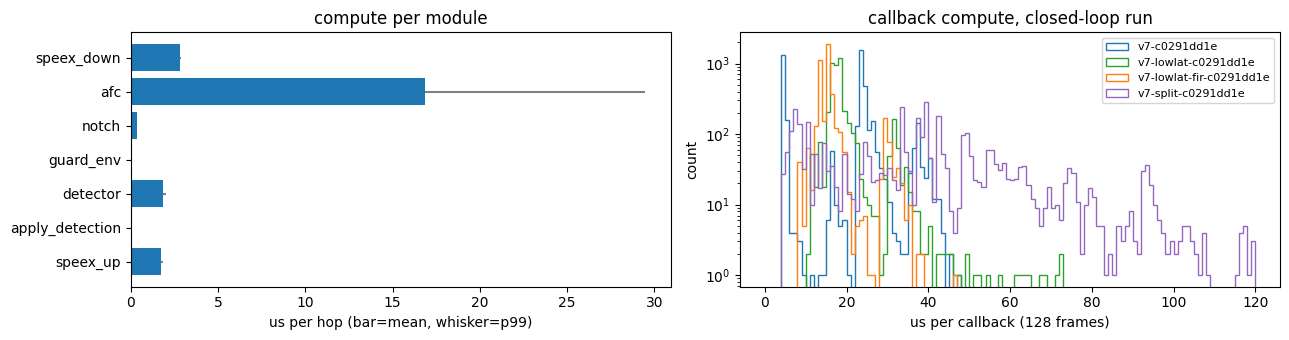

In [9]:
# 4b. compute per module (us per 64-sample hop = 4 ms audio); closed 16 kHz loop keeps detector/notches busy
st = A.stages(30)
order = ["speex_down", "afc", "notch", "guard_env", "detector", "apply_detection", "speex_up"]
where = {"detector": "cb (callback rel) / worker (split)"}
mean = np.array([st[k]["mean"] for k in order]); p99 = np.array([st[k]["p99"] for k in order])
for k, m, p in zip(order, mean, p99):
    print(f"{k:<16} mean {m:7.3f}  p99 {p:7.3f} us  {100 * m / mean.sum():5.1f}%  {where.get(k, 'callback')}")
print(f"total {mean.sum():.2f} us/hop ≈ {mean.sum() * 128 / 192:.1f} us per 128-frame callback")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].barh(order, mean, xerr=[np.zeros_like(p99), p99 - mean], color="tab:blue", ecolor="0.5")
ax[0].set(xlabel="us per hop (bar=mean, whisker=p99)", title="compute per module"); ax[0].invert_yaxis()
for n in RELEASES:
    ax[1].hist(runs[n]["cb_us"], bins=np.linspace(0, 120, 121), histtype="step", color=COLORS[n], label=n)
ax[1].set(xlabel="us per callback (128 frames)", ylabel="count", yscale="log", title="callback compute, closed-loop run")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

drops Q1/Q2: 0/0
cb → Q1 write            mean     1.233  p50     0.375  p99    17.375  max      20.9 us
cb drain Q2              mean     0.467  p50     0.167  p99    10.833  max      19.4 us
Q1 transit (poll)        mean   168.042  p50   185.667  p99   277.167  max    1416.5 us
worker deliver→submit    mean     0.054  p50     0.042  p99     0.084  max       0.5 us
Q2 transit (wait cb)     mean  2498.162  p50  2482.333  p99  3065.000  max    3322.5 us
round trip               mean  2666.258  p50  2665.250  p99  3311.250  max    3410.9 us


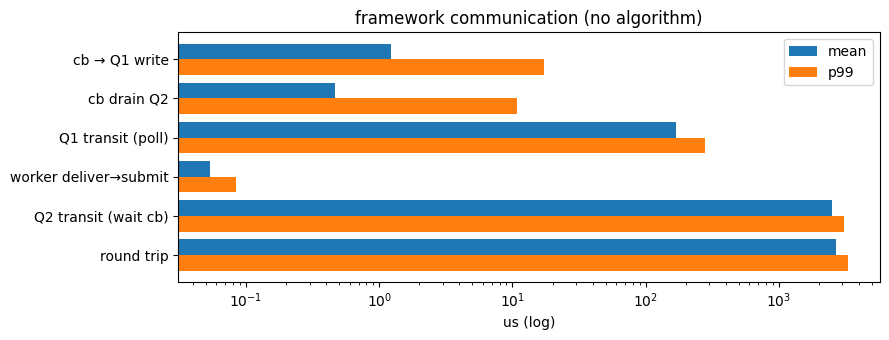

AHS detector work on worker (split) ≈ 1.85 us/hop → add to 'worker' leg


In [10]:
# 4c. communication: timestamp probe on real Engine/Worker, cb paced 2.667 ms (≈10 s wall); no audio → no loop needed
cm = A.comm(10)
legs = ["push_tap", "drain_q2", "q1_transit", "worker", "q2_transit", "round_trip"]
label = {"push_tap": "cb → Q1 write", "drain_q2": "cb drain Q2", "q1_transit": "Q1 transit (poll)",
         "worker": "worker deliver→submit", "q2_transit": "Q2 transit (wait cb)", "round_trip": "round trip"}
print(f"drops Q1/Q2: {cm['analysis_dropped']}/{cm['commands_dropped']}")
for k in legs: print(f"{label[k]:<24} mean {cm[k]['mean']:9.3f}  p50 {cm[k]['p50']:9.3f}  p99 {cm[k]['p99']:9.3f}  max {cm[k]['max']:9.1f} us")
fig, ax = plt.subplots(figsize=(9, 3.5))
y = np.arange(len(legs))
ax.barh(y - .2, [cm[k]["mean"] for k in legs], .4, label="mean"); ax.barh(y + .2, [cm[k]["p99"] for k in legs], .4, label="p99")
ax.set_yticks(y, [label[k] for k in legs]); ax.set_xscale("log"); ax.invert_yaxis()
ax.set(xlabel="us (log)", title="framework communication (no algorithm)"); ax.legend(); plt.tight_layout(); plt.show()
print("AHS detector work on worker (split) ≈", f"{st['detector']['mean']:.2f} us/hop → add to 'worker' leg")

## 5. read-out

- Audio path: v7 = Speex 4.0 + hop wait 2.67 ms; lowlat = Speex only (4.0 ms); lowlat-fir = FIR 1.15 + 1.00 ≈ 2.15 ms. E2E = + device buffers (not measured; needs wired USB + loopback).
- Compute: AFC dominates; total ≪ callback period → not latency, only xrun headroom.
- Comms: queue ops ~0.1–0.3 µs; Q1 ≈ worker poll (≤200 µs); Q2 ≈ wait for next callback → round trip ≈ 1 callback. Control path only (split).
- Suppression (3b): over 6 paths, v7 / lowlat / lowlat-fir have **no systematic difference** in either mode; lower latency ≠ more margin. Single-path gaps are path noise.
- `ahs_sim` gap (3c): its +13.9 dB comes from a short modal path, `tanh` speaker, last-1-s criterion. With the same path/criterion/speaker this loop lands in `ahs_sim`'s range → rt-audio itself costs ~0. Both sims are models; real RIRs + contract criteria needed.
- Split callback compute higher when paced in real time (idle gaps: likely CPU clock/cache) vs unpaced runs.
- Outputs: `notebook/out/*.wav`, `*.f32`.